# setup + imports

In [1]:
pip install torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

In [3]:
import numpy as np
import os
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

# load variational autoencoder
encoder = torch.load('mnist_cvae8_encoder.pth', weights_only=False, map_location=device)
decoder = torch.load('mnist_cvae8_decoder.pth', weights_only=False, map_location=device)
encoder.eval()
decoder.eval()

cpu


Sequential(
  (0): Linear(in_features=8, out_features=1568, bias=True)
  (1): ReLU()
  (2): Unflatten(dim=1, unflattened_size=(32, 7, 7))
  (3): ConvTranspose2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): ConvTranspose2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (6): ReLU()
  (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU()
  (10): ConvTranspose2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (11): ReLU()
  (12): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (13): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (14): Sigmoid()
)

In [4]:
import os
print(os.listdir("train_data")[:5])

['3975.png', '8820.png', '9280.png', '1804.png', '4968.png']


In [5]:
'''


# run autocoder
def autoencoder(x, latent_dim=8):
    return decoder(encoder(x)[:,:latent_dim])

# Load image
directory = "train_data"
i=98
transform = transforms.ToTensor()
img = transform(Image.open(f"{directory}/{i:04d}.png"))

# Process image
batch = img.unsqueeze(0).to(device)
with torch.no_grad():
    result = autoencoder(batch)

# Display result
plt.imshow((result.squeeze(0).squeeze(0).cpu().numpy()*255).astype(np.uint8),cmap='gray')
plt.show()
'''

'\n\n\n# run autocoder\ndef autoencoder(x, latent_dim=8):\n    return decoder(encoder(x)[:,:latent_dim])\n\n# Load image\ndirectory = "train_data"\ni=98\ntransform = transforms.ToTensor()\nimg = transform(Image.open(f"{directory}/{i:04d}.png"))\n\n# Process image\nbatch = img.unsqueeze(0).to(device)\nwith torch.no_grad():\n    result = autoencoder(batch)\n\n# Display result\nplt.imshow((result.squeeze(0).squeeze(0).cpu().numpy()*255).astype(np.uint8),cmap=\'gray\')\nplt.show()\n'

# subtask 1

In [6]:
def binarize(x):
    return (x > 0.5).float()

directory = 'train_data'
nrpoze = 0
for elem in os.listdir(directory):
    if elem.endswith('.png'):
        nrpoze += 1
print(nrpoze) 

poze = []
for i in range(10000):
    transform = transforms.ToTensor()
    img = transform(Image.open(f"{directory}/{i:04d}.png"))
    poze.append(img)

nr = 0
for img in poze:
    if torch.equal(binarize(img), img):
        nr += 1

percentage = round(100 * nr / nrpoze, 2)
print(percentage)

10000
100.0


# subtask 2

In [7]:
def autoencoder(x, latent_dim=8):
    return decoder(encoder(x)[:,:latent_dim])

erori = []
for img in poze:
    batch = img.unsqueeze(0).to(device)
    with torch.no_grad():
        result = autoencoder(batch)
    rec = result.squeeze(0).cpu()
    err = torch.mean((rec-img)**2).item()
    erori.append(err)

maxi = round(max(erori), 5)
print(maxi)


0.21746


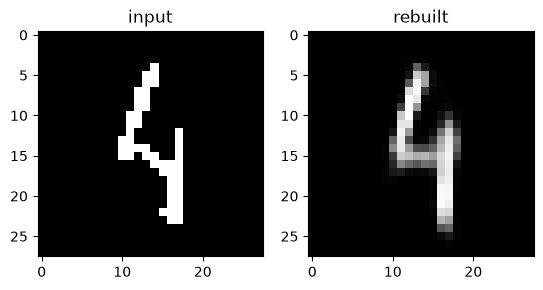

In [8]:
# testare reconstruiction
plt.subplot(1, 2, 1); plt.imshow(img[0], cmap='gray'); plt.title('input')
plt.subplot(1, 2, 2); plt.imshow(rec[0], cmap='gray'); plt.title('rebuilt')
plt.show()

# subtask 3

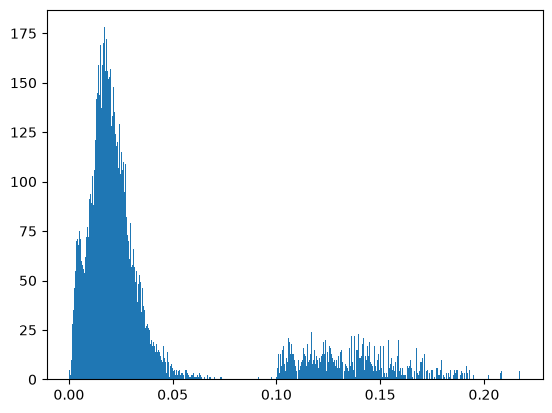

[0.02161836 0.03021969 0.0423361  0.12762314 0.14748625 0.17895316]


In [9]:
erori = np.array(erori)
plt.hist(erori, bins=500)
plt.show()
print(np.percentile(erori, [50, 70, 80, 90, 95, 99]))

In [10]:
threshold = 0.075
count = 0
ans3 = []
for e in erori: 
    if e > threshold:
        ans3.append(1)
        count += 1
    else:
        ans3.append(0)

# subtask 5

copiat dar idc i was runing out of time

In [13]:
from sklearn.cluster import KMeans

letters = []                          # image numbers flagged as letters
for i in range(len(ans3)):
    if ans3[i] == 1:
        letters.append(i)

L = []
for i in letters:
    L.append(poze[i].squeeze(0).numpy().flatten())     # 28x28 -> 784 numbers
L = np.array(L)

K = 50
clusters = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(L)

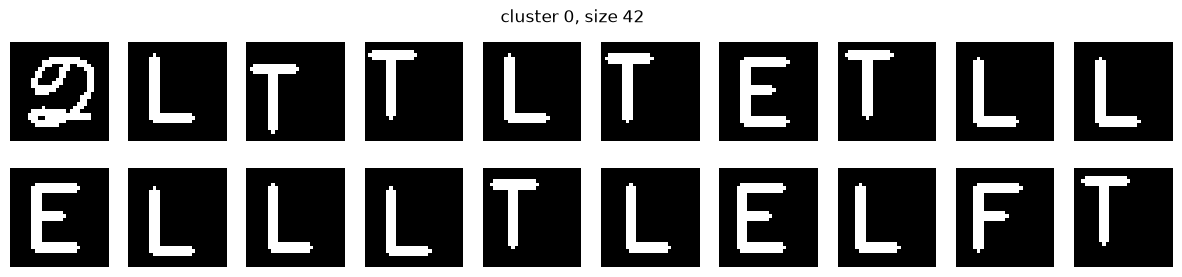

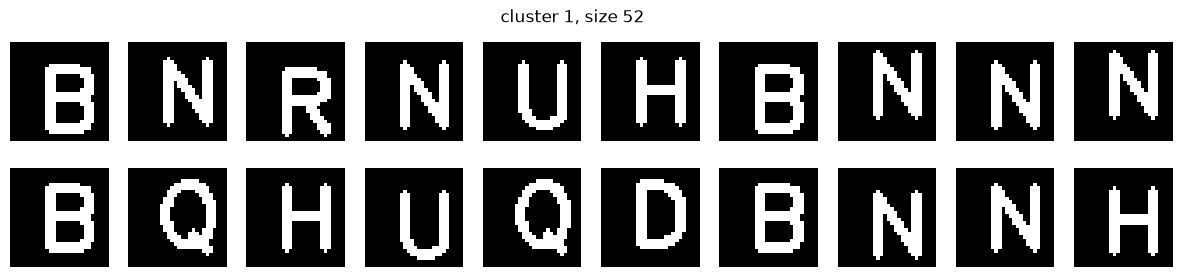

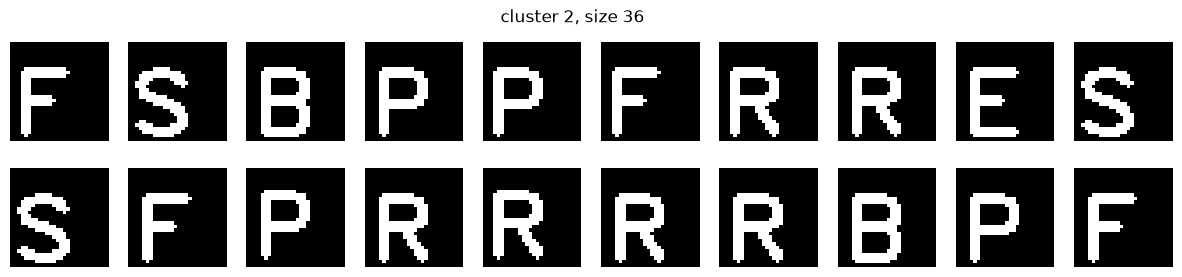

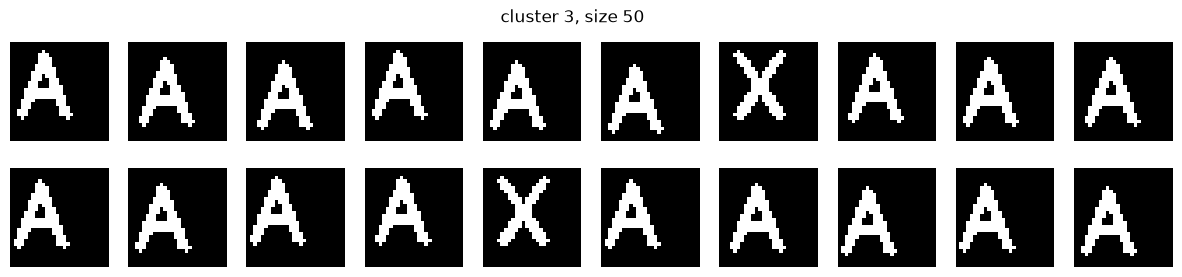

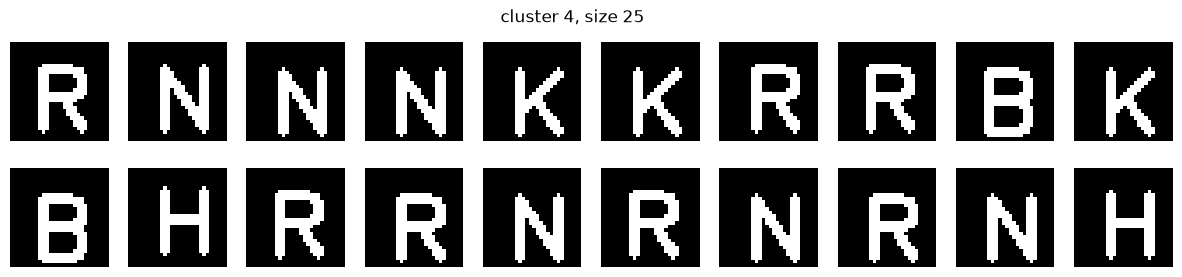

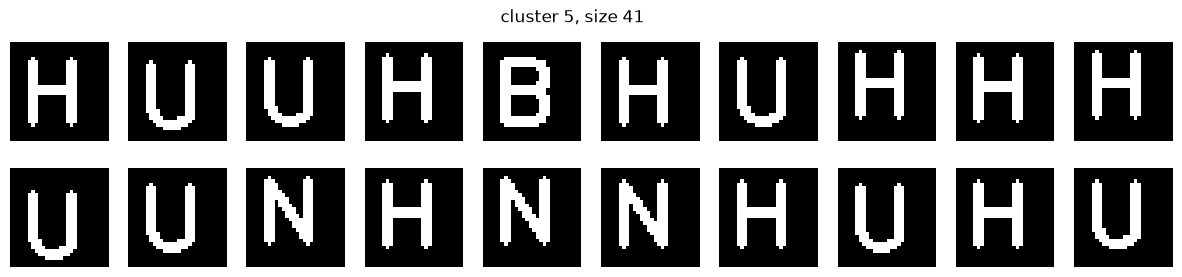

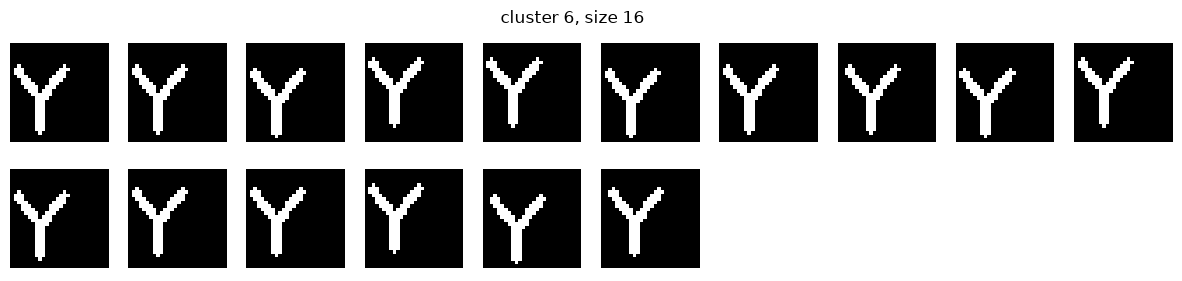

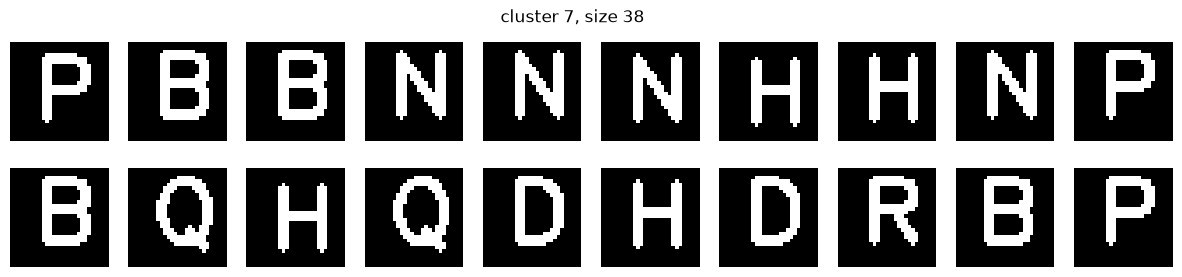

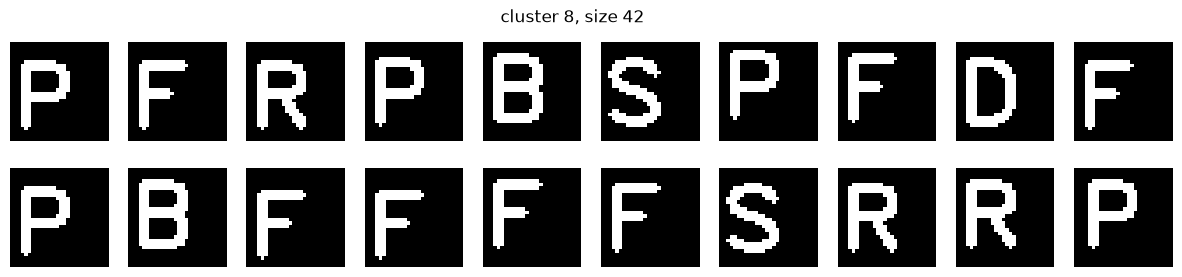

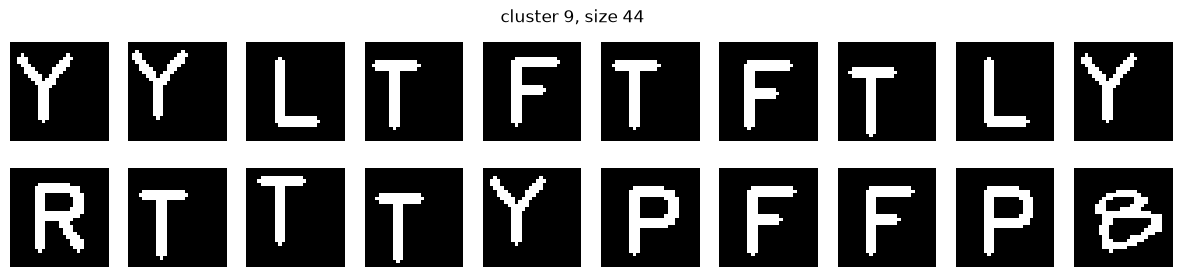

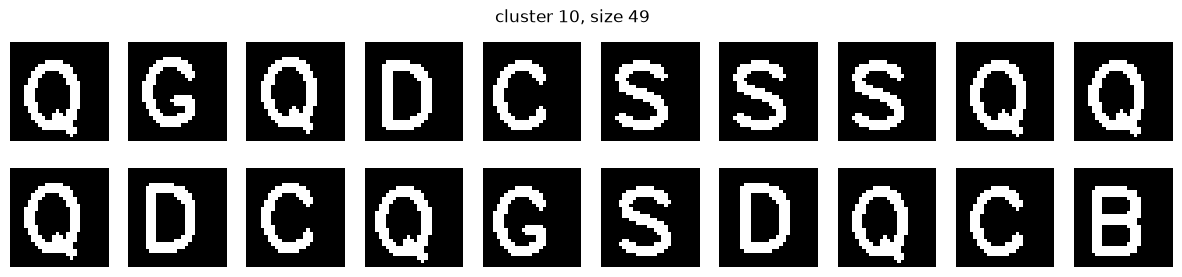

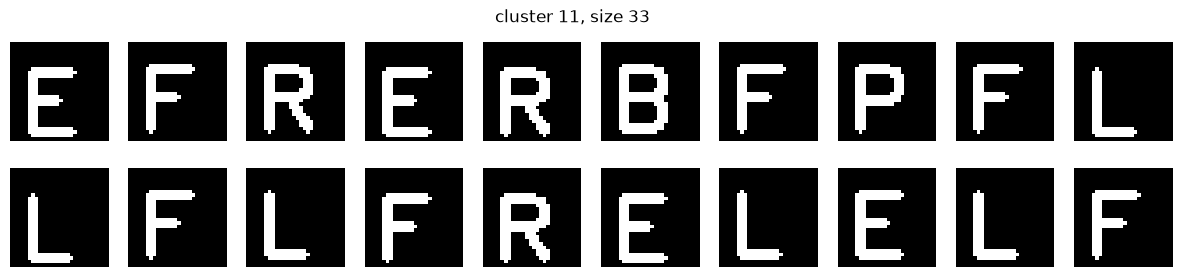

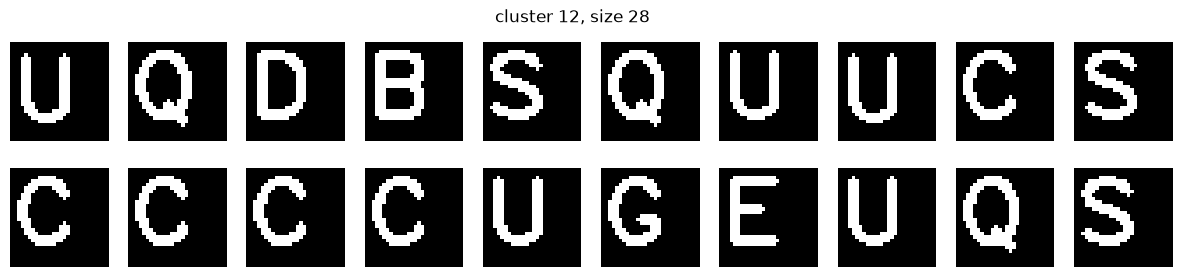

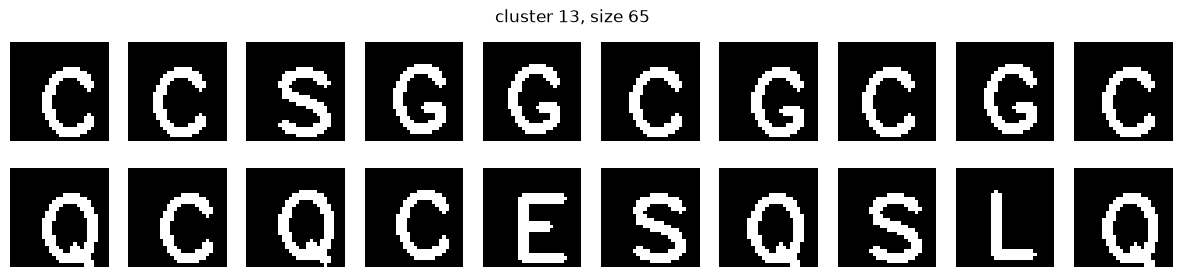

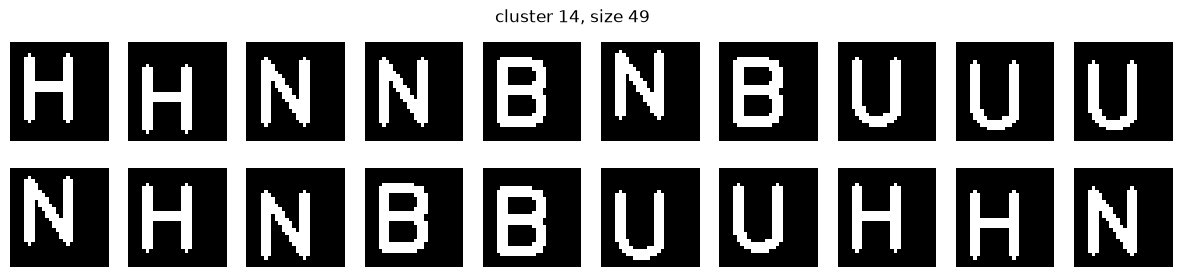

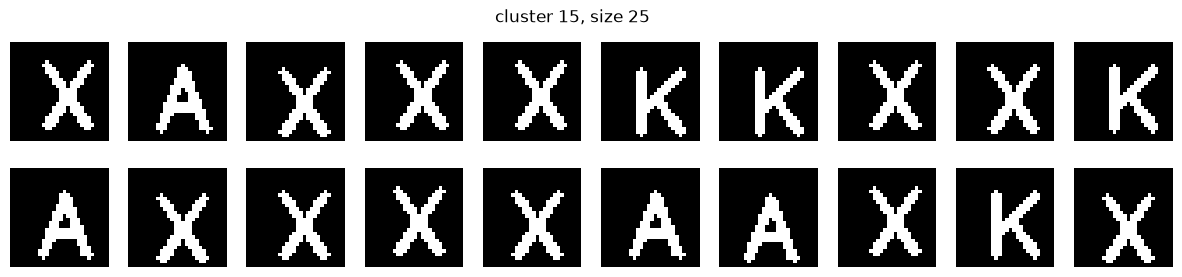

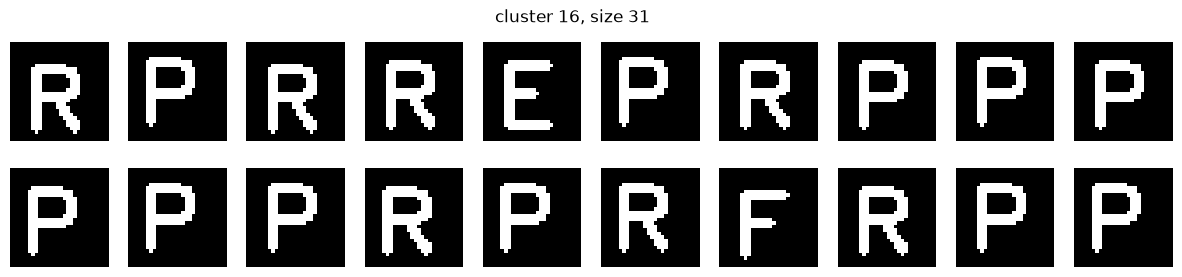

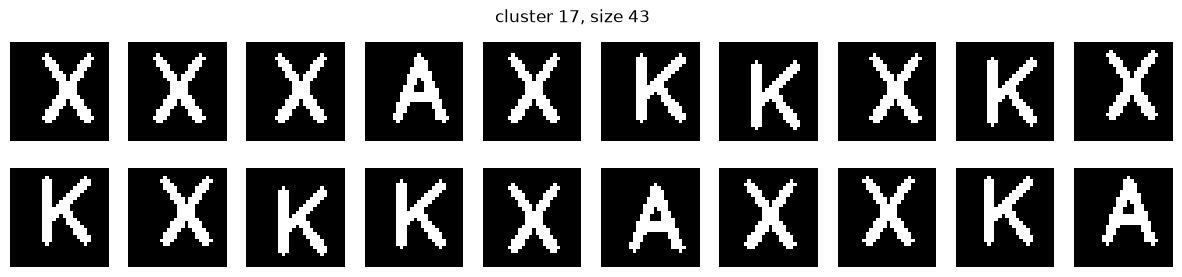

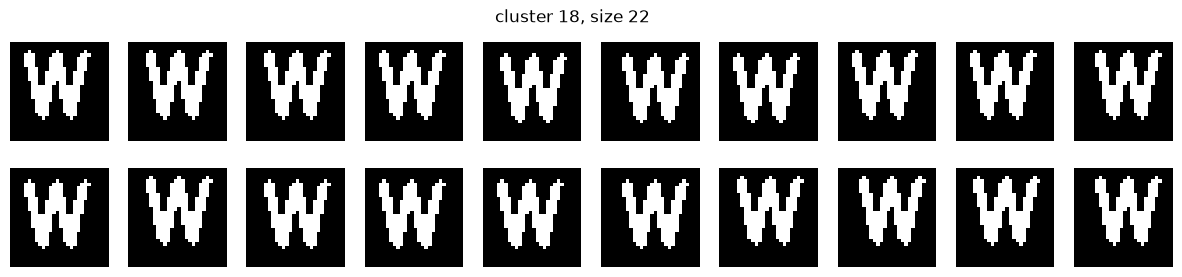

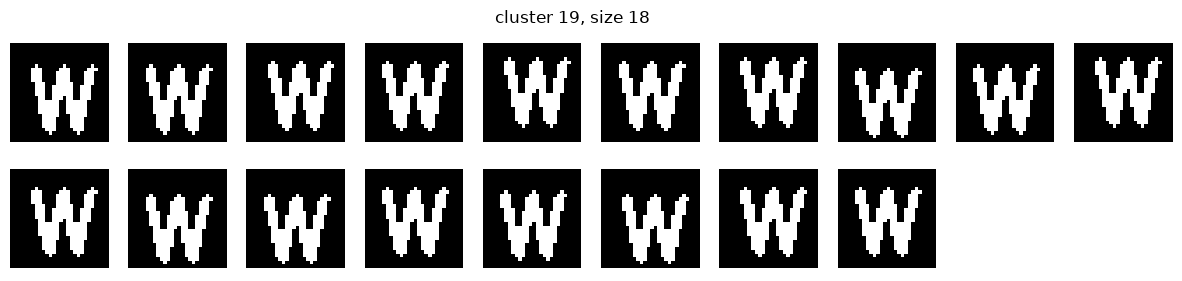

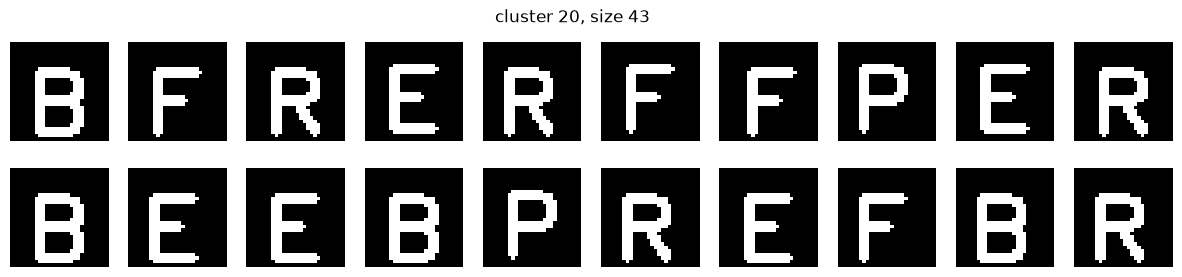

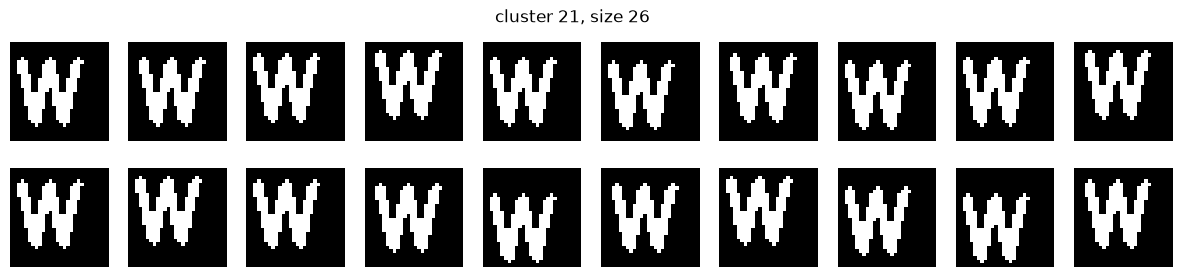

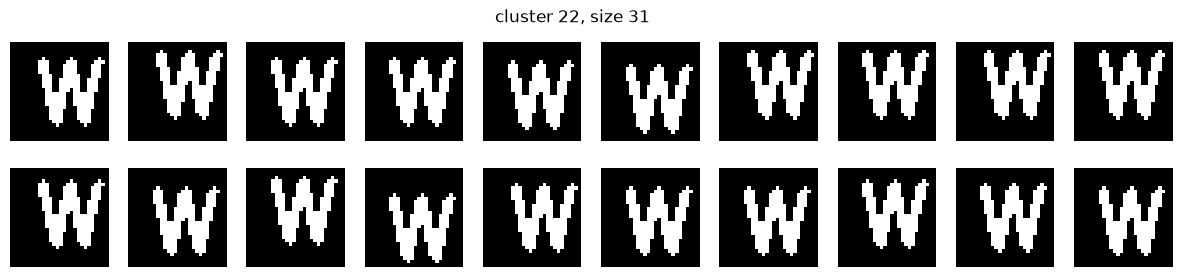

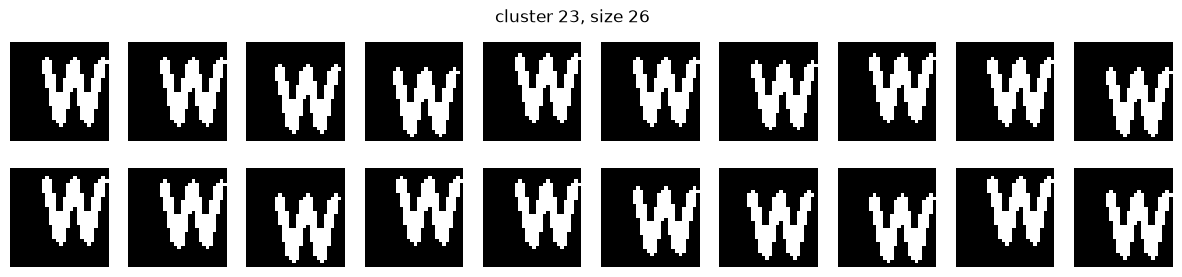

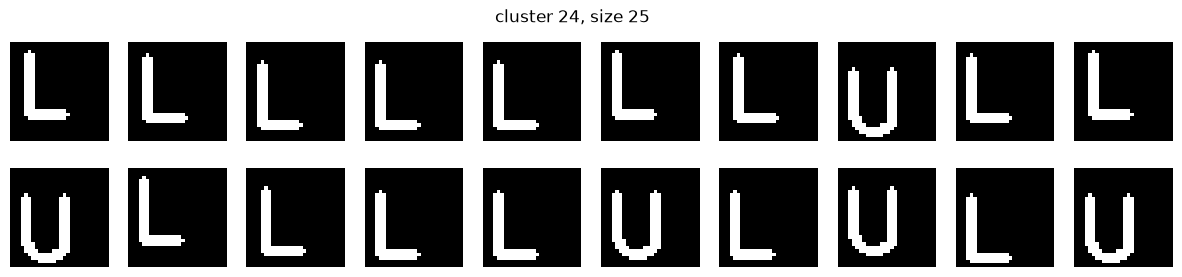

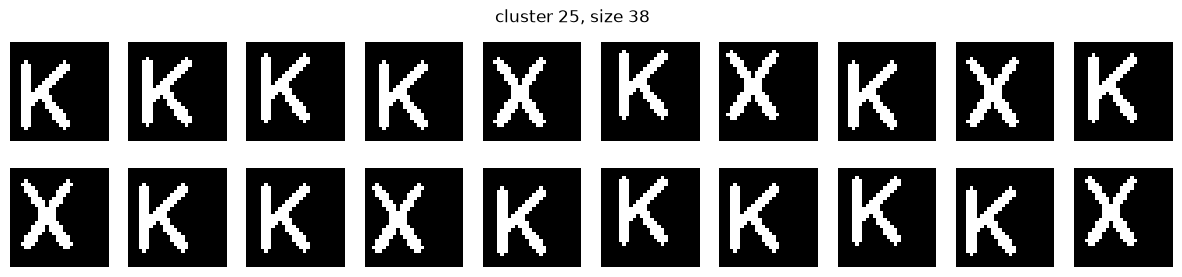

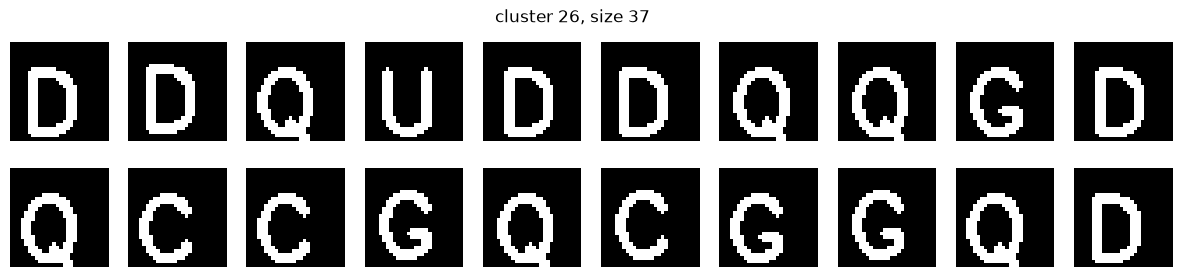

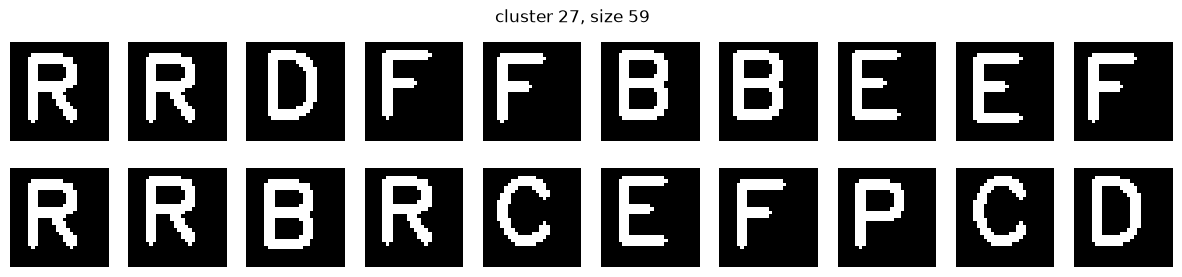

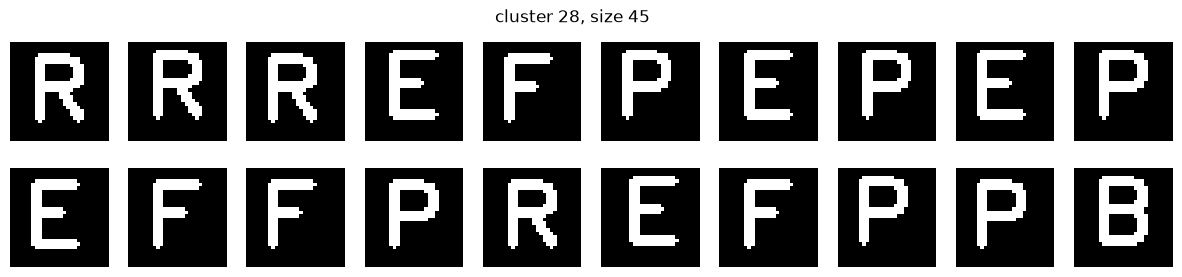

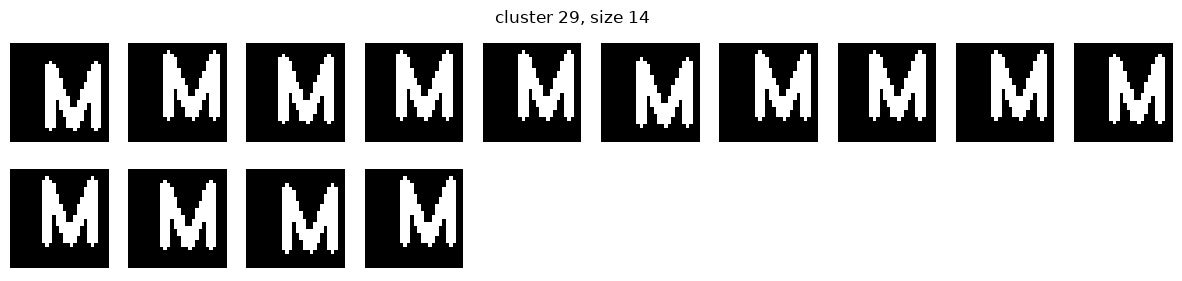

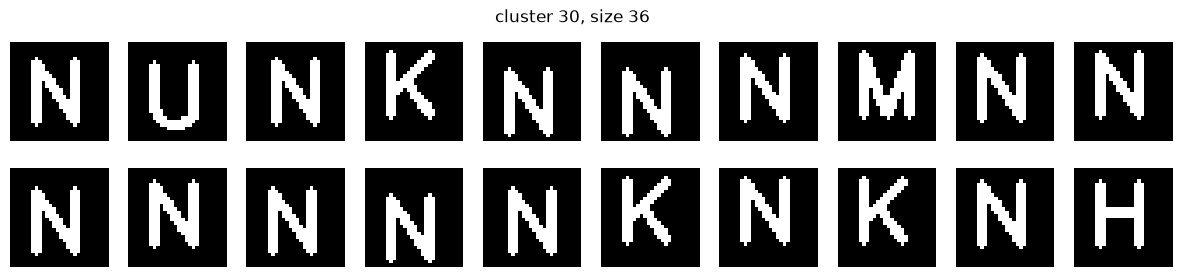

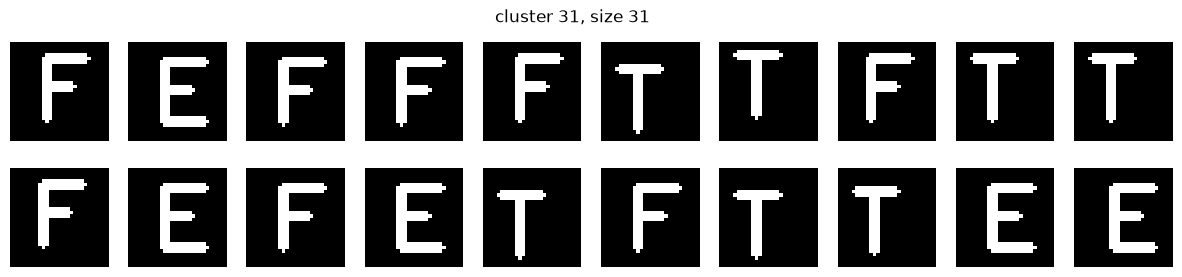

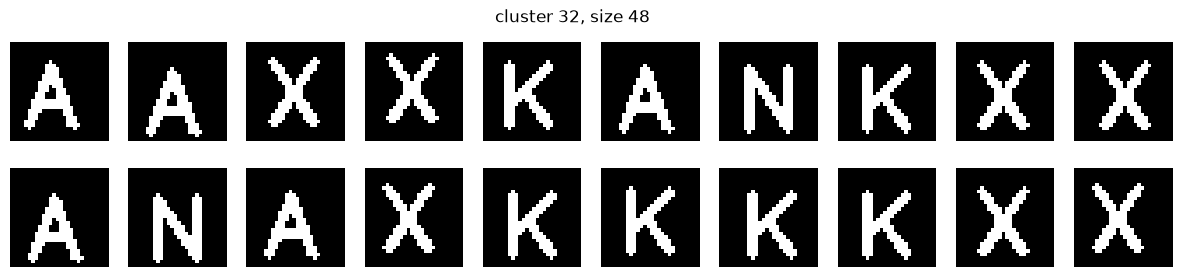

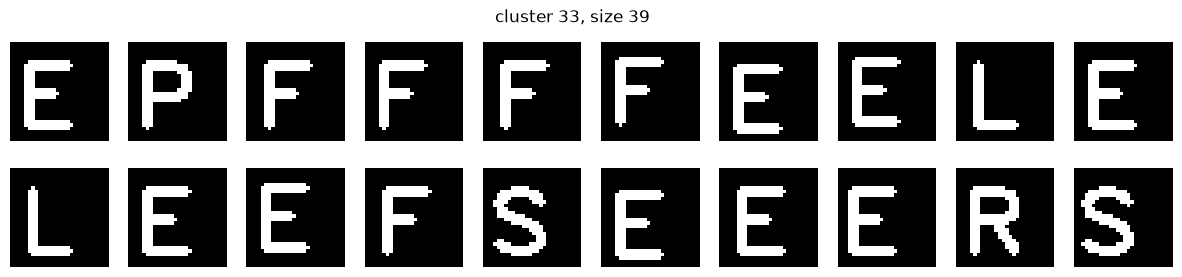

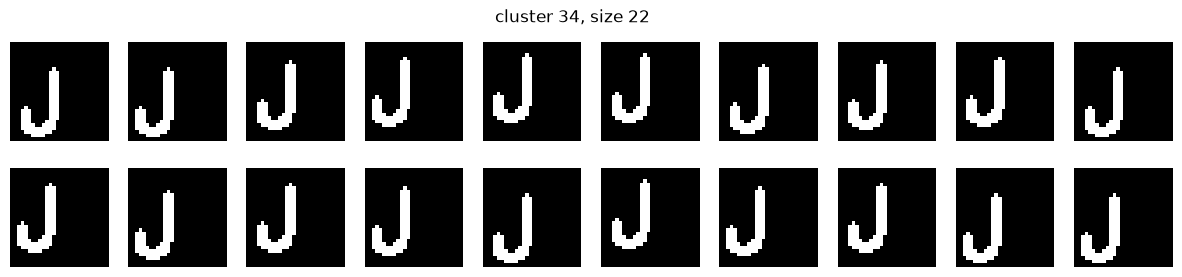

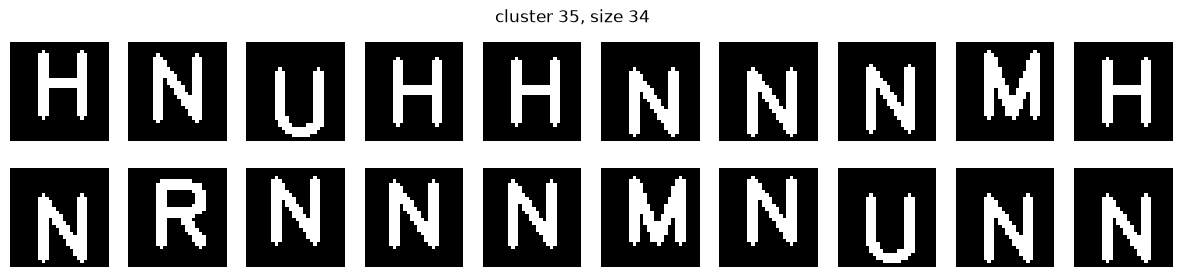

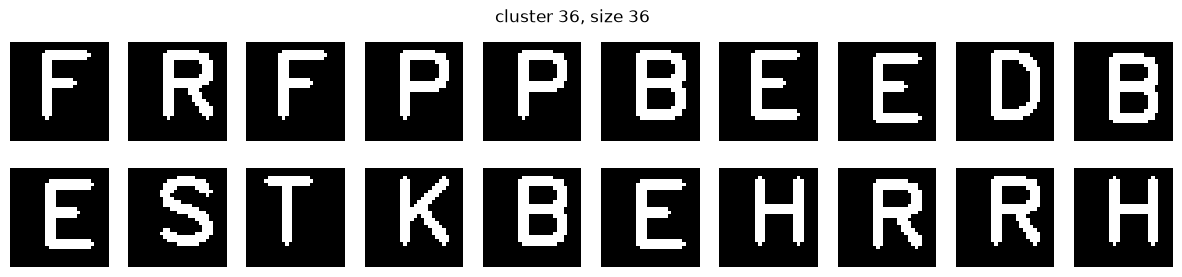

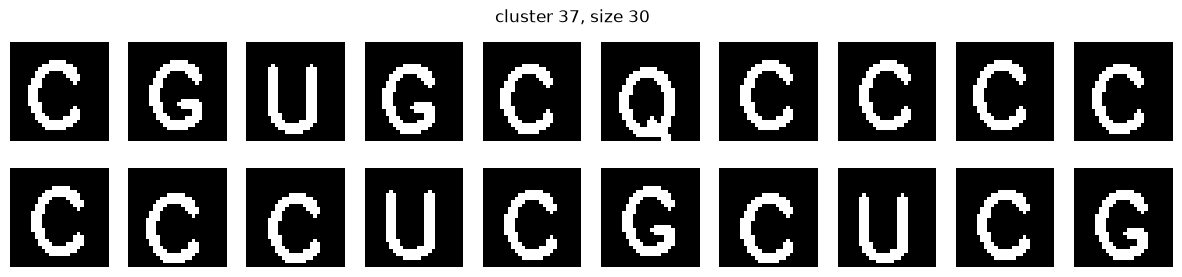

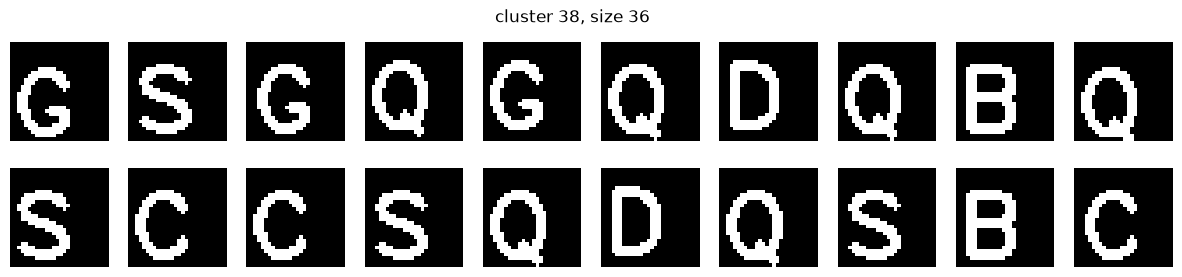

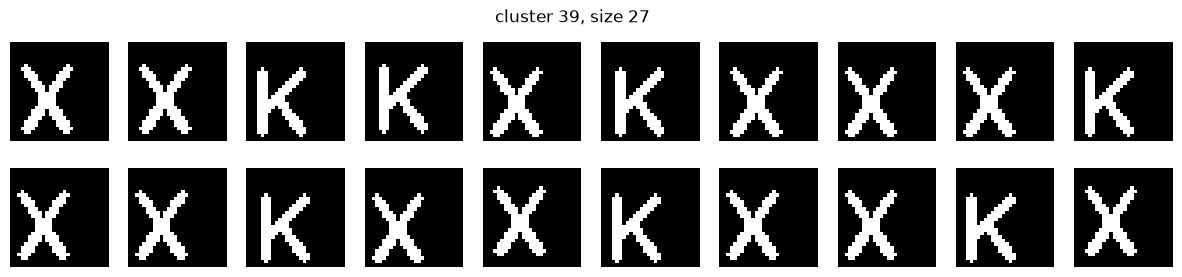

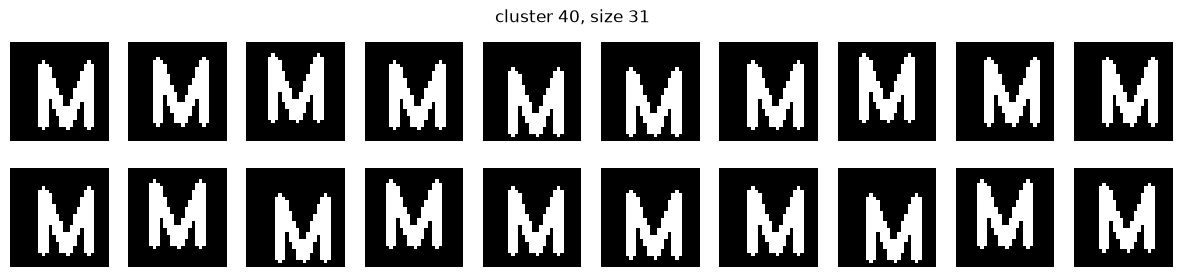

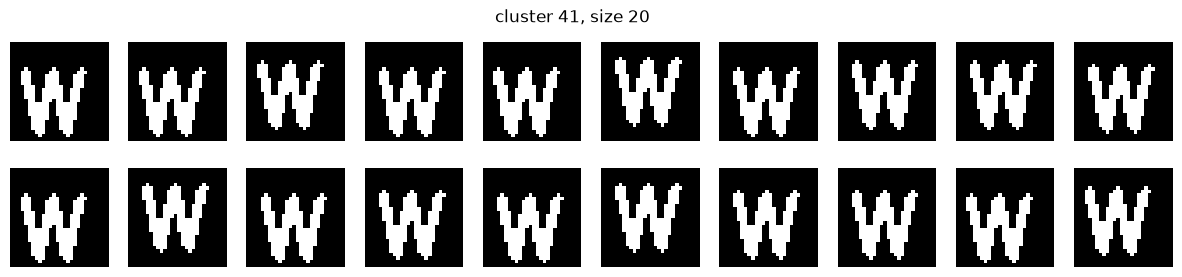

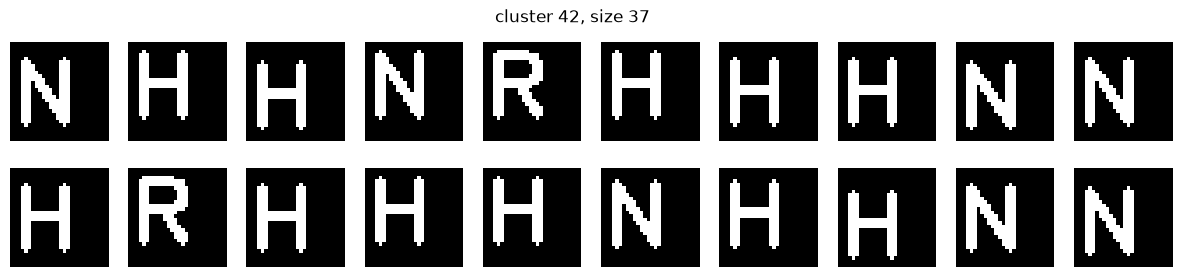

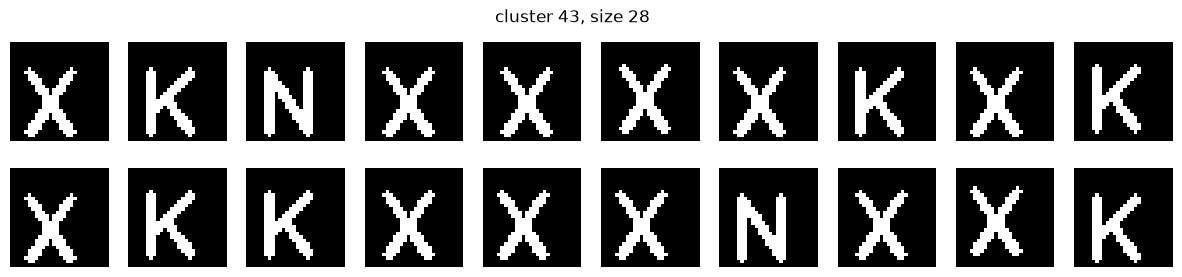

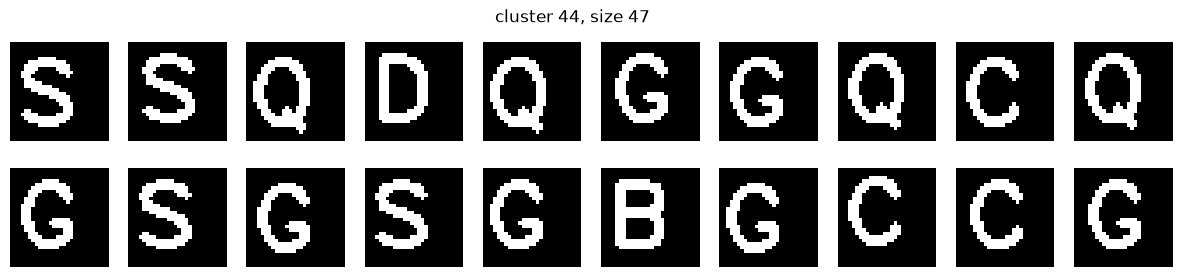

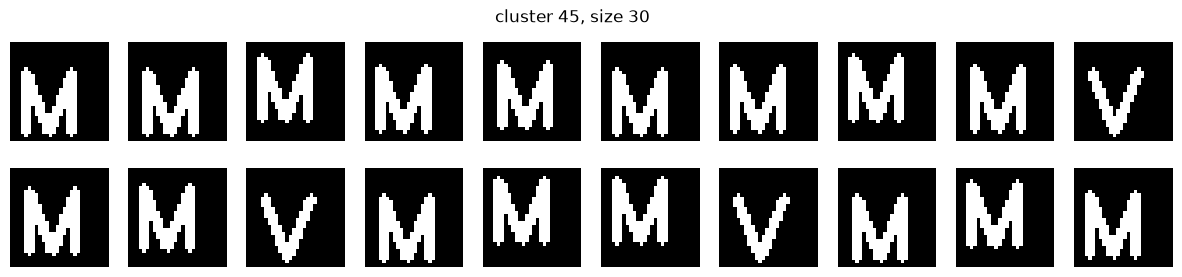

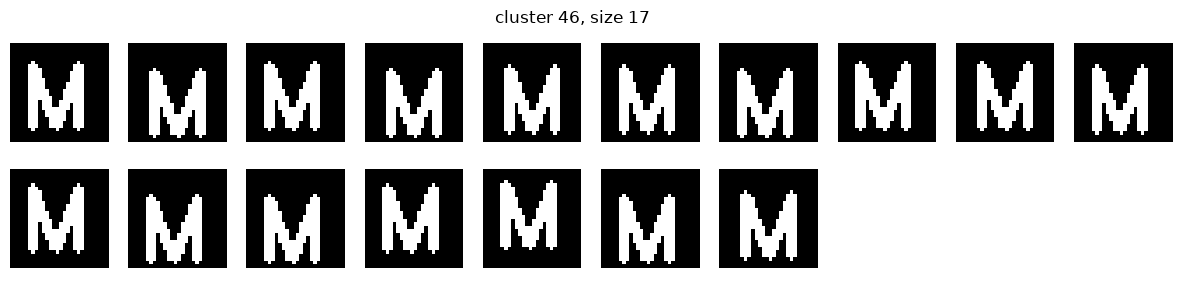

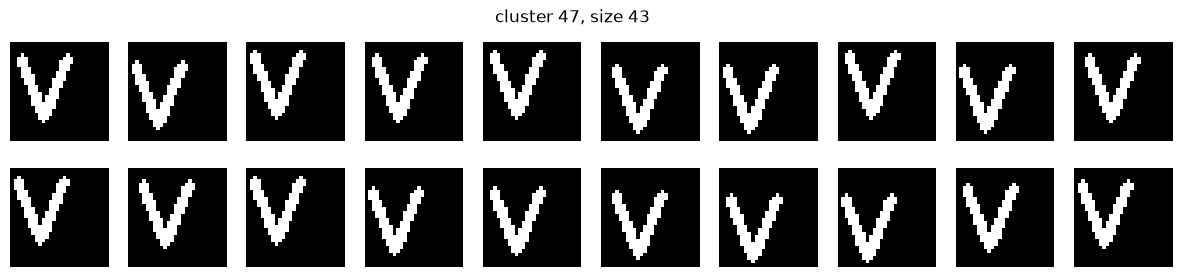

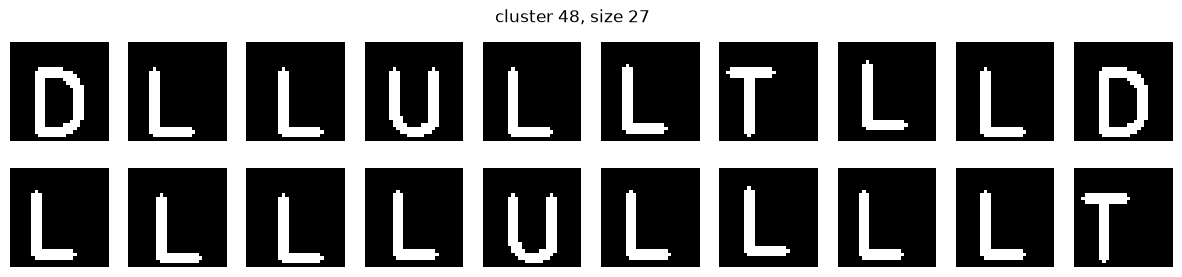

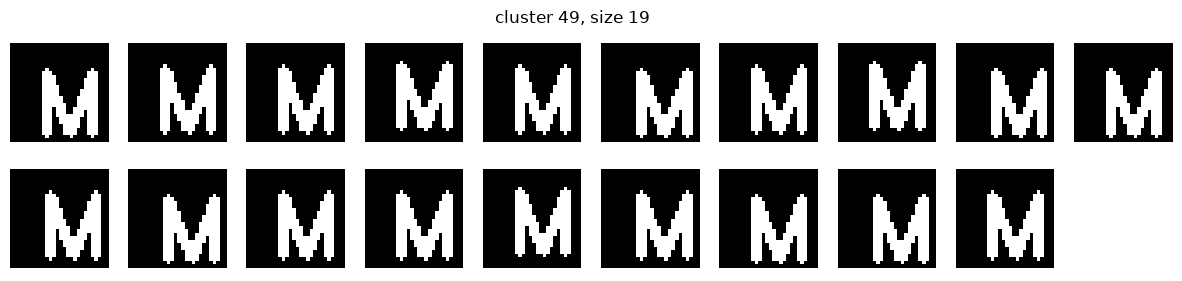

In [14]:
def show_cluster(c):
    rows = []
    for k in range(len(letters)):
        if clusters[k] == c:
            rows.append(letters[k])
    fig, axes = plt.subplots(2, 10, figsize=(15, 3))
    axes = axes.flatten()
    for k in range(20):
        axes[k].axis('off')
        if k < len(rows):
            axes[k].imshow(poze[rows[k]].squeeze(0).numpy(), cmap='gray')
    fig.suptitle(f'cluster {c}, size {len(rows)}')
    plt.show()

for c in range(K):
    show_cluster(c)

# submission

In [12]:
rows = []

# Subtask 1
rows.append([1, 0, percentage])

# Subtask 2
rows.append([2, 0, maxi])

# Subtask 3
for i, label in enumerate(ans3):
    rows.append([3, i, label])

# Subtask 4
rows.append([4, 0, count])

# Subtask 5
letters = 'ABCD'
indices = []
characters = [' ']*10000
for index, letter in zip(indices, letters):
    characters[index] = letter
for i, character in enumerate(characters):
    rows.append([5, i, character])

# save to CSV (no header)
df = pd.DataFrame(rows, columns=["subtaskID", "datapointID", "answer"])
df.to_csv("popoluska.csv", index=False, header=True)